<a href="https://colab.research.google.com/github/nr868848-stack/Bank-loan-default-risk-predictio/blob/main/Bank_loan_default_risk_prediction_and_using_machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# PROJECT: BANK LOAN DEFAULT RISK PREDICTION
# AUTHOR: Data Science Portfolio Project
# OBJECTIVE: Predict loan default risk using Machine Learning
# ============================================================

# STEP 1: IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

np.random.seed(42)

print("All libraries imported successfully!")
print("Bank Loan Default Risk Prediction Project Started.")

All libraries imported successfully!
Bank Loan Default Risk Prediction Project Started.


In [ ]:
# ============================================================
# STEP 2: CREATE SYNTHETIC BANK LOAN DATASET
# ============================================================

n = 2000

age = np.random.randint(21, 66, n)

annual_income = np.random.randint(150000, 1500001, n)

employment_years = np.array([
    np.random.randint(0, min(41, max(1, a - 18)))
    for a in age
])

credit_score = np.clip(
    np.random.normal(680, 70, n),
    300,
    850
).astype(int)

loan_amount = np.random.randint(50000, 1000001, n)

interest_rate = np.round(
    np.random.uniform(7, 20, n), 2
)

existing_loans hu= np.random.randint(0, 6, n)

debt_to_income = np.round(
    np.random.uniform(0.05, 0.80, n), 2
)

payment_history = np.random.randint(0, 13, n)

education = np.random.choice(
    ["Graduate", "Postgraduate", "High School"],
    n,
    p=[0.50, 0.20, 0.30]
)

employment_type = np.random.choice(
    ["Salaried", "Self-Employed", "Business"],
    n
)

# Create a probability score for demonstration.
# This is a simulated rule, not a real banking formula.

risk_score = (
    -2.0
    + 0.018 * (680 - credit_score)
    + 0.045 * (interest_rate - 12)
    + 2.0 * debt_to_income
    + 0.35 * existing_loans
    + 0.8 * (payment_history <= 3)
    + 0.7 * (loan_amount > annual_income * 0.7)
)

default_probability = 1 / (1 + np.exp(-risk_score))

loan_default = np.random.binomial(
    1,
    default_probability
)

df = pd.DataFrame({
    "Age": age,
    "Annual_Income": annual_income,
    "Employment_Years": employment_years,
    "Credit_Score": credit_score,
    "Loan_Amount": loan_amount,
    "Interest_Rate": interest_rate,
    "Existing_Loans": existing_loans,
    "Debt_To_Income": debt_to_income,
    "Payment_History_Late_Count": payment_history,
    "Education": education,
    "Employment_Type": employment_type,
    "Loan_Default": loan_default
})

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

df.head(10)

Dataset created successfully!
Dataset shape: (2000, 12)


,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Education,Employment_Type,Loan_Default
0,59,1194257,30,715,510258,8.63,4,0.70,7,High School,Salaried,1
1,49,198320,3,505,887742,17.22,2,0.23,7,Graduate,Self-Employed,1
2,35,1114918,11,612,917190,7.23,5,0.11,2,Graduate,Business,1
3,63,646758,22,794,193435,13.28,2,0.52,2,High School,Business,0
4,28,1345225,1,639,528365,11.30,0,0.30,4,High School,Self-Employed,1
5,41,1323930,21,597,867060,16.62,5,0.55,2,Graduate,Business,1
6,59,762297,36,666,554136,11.07,1,0.07,4,High School,Salaried,1
7,39,598625,7,824,119672,17.75,0,0.15,7,Graduate,Business,0
8,43,178625,6,551,620534,14.73,1,0.56,0,Graduate,Self-Employed,1
9,31,886400,7,606,978665,17.32,5,0.21,1,Postgraduate,Self-Employed,1


In [ ]:
# ============================================================
# STEP 3: INITIAL DATA EXPLORATION
# ============================================================

print("First 10 Records:")
display(df.head(10))

print("\nLast 5 Records:")
display(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

First 10 Records:


,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Education,Employment_Type,Loan_Default
0,59,1194257,30,715,510258,8.63,4,0.70,7,High School,Salaried,1
1,49,198320,3,505,887742,17.22,2,0.23,7,Graduate,Self-Employed,1
2,35,1114918,11,612,917190,7.23,5,0.11,2,Graduate,Business,1
3,63,646758,22,794,193435,13.28,2,0.52,2,High School,Business,0
4,28,1345225,1,639,528365,11.30,0,0.30,4,High School,Self-Employed,1
5,41,1323930,21,597,867060,16.62,5,0.55,2,Graduate,Business,1
6,59,762297,36,666,554136,11.07,1,0.07,4,High School,Salaried,1
7,39,598625,7,824,119672,17.75,0,0.15,7,Graduate,Business,0
8,43,178625,6,551,620534,14.73,1,0.56,0,Graduate,Self-Employed,1
9,31,886400,7,606,978665,17.32,5,0.21,1,Postgraduate,Self-Employed,1



Last 5 Records:


,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Education,Employment_Type,Loan_Default
1995,28,447675,9,573,577169,11.43,3,0.37,10,Graduate,Salaried,0
1996,49,858175,2,715,882345,14.04,5,0.67,7,High School,Business,1
1997,52,413625,33,723,686148,15.78,3,0.06,12,High School,Salaried,0
1998,58,992840,34,593,921217,15.23,1,0.13,9,Postgraduate,Self-Employed,1
1999,25,350339,5,574,508253,13.01,4,0.79,1,Graduate,Business,1



Dataset Shape:
(2000, 12)

Column Names:
['Age', 'Annual_Income', 'Employment_Years', 'Credit_Score', 'Loan_Amount', 'Interest_Rate', 'Existing_Loans', 'Debt_To_Income', 'Payment_History_Late_Count', 'Education', 'Employment_Type', 'Loan_Default']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         2000 non-null   int64  
 1   Annual_Income               2000 non-null   int64  
 2   Employment_Years            2000 non-null   int64  
 3   Credit_Score                2000 non-null   int64  
 4   Loan_Amount                 2000 non-null   int64  
 5   Interest_Rate               2000 non-null   float64
 6   Existing_Loans              2000 non-null   int64  
 7   Debt_To_Income              2000 non-null   float64
 8   Payment_History_Late_Count  2000 non-null   int

,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Education,Employment_Type,Loan_Default
count,2000.000000,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000,2000,2000.00000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate,Self-Employed,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1011,690,NaN
mean,43.306000,8.277354e+05,12.146500,676.598500,540077.588000,13.499940,2.524500,0.422605,5.969000,NaN,NaN,0.57250
std,12.931704,3.852673e+05,10.007803,68.965008,274419.100422,3.754613,1.709638,0.220058,3.753943,NaN,NaN,0.49484
min,21.000000,1.501590e+05,0.000000,457.000000,50037.000000,7.000000,0.000000,0.050000,0.000000,NaN,NaN,0.00000
25%,32.000000,4.882520e+05,3.750000,630.750000,310170.250000,10.337500,1.000000,0.230000,3.000000,NaN,NaN,0.00000
50%,44.000000,8.282080e+05,10.000000,678.000000,547748.000000,13.540000,3.000000,0.420000,6.000000,NaN,NaN,1.00000
75%,54.000000,1.171638e+06,19.000000,724.000000,783034.000000,16.732500,4.000000,0.620000,9.000000,NaN,NaN,1.00000



Data Types:
Age                             int64
Annual_Income                   int64
Employment_Years                int64
Credit_Score                    int64
Loan_Amount                     int64
Interest_Rate                 float64
Existing_Loans                  int64
Debt_To_Income                float64
Payment_History_Late_Count      int64
Education                      object
Employment_Type                object
Loan_Default                    int64
dtype: object

Missing Values:
Age                           0
Annual_Income                 0
Employment_Years              0
Credit_Score                  0
Loan_Amount                   0
Interest_Rate                 0
Existing_Loans                0
Debt_To_Income                0
Payment_History_Late_Count    0
Education                     0
Employment_Type               0
Loan_Default                  0
dtype: int64

Duplicate Rows:
0


In [ ]:
# ============================================================
# STEP 4: DATA CLEANING
# ============================================================

df_clean = df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Handle missing numerical values
numeric_columns = df_clean.select_dtypes(
    include=["number"]
).columns.tolist()

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Handle missing categorical values
categorical_columns = df_clean.select_dtypes(
    include=["object"]
).columns.tolist()

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

# Remove invalid target records if present
df_clean = df_clean[
    df_clean["Loan_Default"].isin([0, 1])
].copy()

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicates after cleaning:")
print(df_clean.duplicated().sum())

print("\nCleaned dataset shape:")
print(df_clean.shape)

display(df_clean.head())

Missing values before cleaning:
Age                           0
Annual_Income                 0
Employment_Years              0
Credit_Score                  0
Loan_Amount                   0
Interest_Rate                 0
Existing_Loans                0
Debt_To_Income                0
Payment_History_Late_Count    0
Education                     0
Employment_Type               0
Loan_Default                  0
dtype: int64

Missing values after cleaning:
Age                           0
Annual_Income                 0
Employment_Years              0
Credit_Score                  0
Loan_Amount                   0
Interest_Rate                 0
Existing_Loans                0
Debt_To_Income                0
Payment_History_Late_Count    0
Education                     0
Employment_Type               0
Loan_Default                  0
dtype: int64

Duplicates after cleaning:
0

Cleaned dataset shape:
(2000, 12)


,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Education,Employment_Type,Loan_Default
0,59,1194257,30,715,510258,8.63,4,0.70,7,High School,Salaried,1
1,49,198320,3,505,887742,17.22,2,0.23,7,Graduate,Self-Employed,1
2,35,1114918,11,612,917190,7.23,5,0.11,2,Graduate,Business,1
3,63,646758,22,794,193435,13.28,2,0.52,2,High School,Business,0
4,28,1345225,1,639,528365,11.30,0,0.30,4,High School,Self-Employed,1


In [ ]:
# ============================================================
# STEP 5: EXPLORATORY DATA ANALYSIS
# ============================================================

# Default distribution
default_counts = df_clean["Loan_Default"].value_counts().sort_index()

print("Loan Default Distribution:")
print(default_counts)

# Default percentage
default_percentage = (
    df_clean["Loan_Default"].value_counts(normalize=True) * 100
)

print("\nDefault Percentage:")
print(default_percentage)

# Plot 1: Default Distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Loan_Default"
)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Plot 2: Credit Score Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Credit_Score",
    bins=30,
    kde=True
)

plt.title("Credit Score Distribution")
plt.tight_layout()
plt.show()

# Plot 3: Annual Income Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Annual_Income",
    bins=30,
    kde=True
)

plt.title("Annual Income Distribution")
plt.tight_layout()
plt.show()

# Plot 4: Loan Amount by Default Status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Loan_Default",
    y="Loan_Amount"
)

plt.title("Loan Amount vs Default Status")
plt.tight_layout()
plt.show()

# Plot 5: Credit Score vs Default Status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Loan_Default",
    y="Credit_Score"
)

plt.title("Credit Score vs Default Status")
plt.tight_layout()
plt.show()

# Plot 6: Default Rate by Employment Type
employment_default_rate = (
    df_clean.groupby("Employment_Type")["Loan_Default"]
    .mean()
    .sort_values(ascending=False)
)

print("\nDefault Rate by Employment Type:")
print(employment_default_rate)

employment_default_rate.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Default Rate by Employment Type")
plt.ylabel("Default Rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Correlation Matrix:


,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Loan_Default
Age,1.00,0.01,0.61,0.02,0.02,-0.00,0.00,-0.00,-0.02,-0.01
Annual_Income,0.01,1.00,-0.01,0.03,-0.03,0.01,0.01,0.01,-0.02,-0.06
Employment_Years,0.61,-0.01,1.00,0.02,0.05,-0.01,-0.02,0.00,0.01,-0.00
Credit_Score,0.02,0.03,0.02,1.00,-0.02,0.04,-0.02,0.01,-0.03,-0.42
Loan_Amount,0.02,-0.03,0.05,-0.02,1.00,0.01,0.03,-0.00,-0.01,0.10
Interest_Rate,-0.00,0.01,-0.01,0.04,0.01,1.00,-0.03,-0.02,-0.03,0.04
Existing_Loans,0.00,0.01,-0.02,-0.02,0.03,-0.03,1.00,0.02,-0.05,0.23
Debt_To_Income,-0.00,0.01,0.00,0.01,-0.00,-0.02,0.02,1.00,0.01,0.11
Payment_History_Late_Count,-0.02,-0.02,0.01,-0.03,-0.01,-0.03,-0.05,0.01,1.00,-0.07
Loan_Default,-0.01,-0.06,-0.00,-0.42,0.10,0.04,0.23,0.11,-0.07,1.00


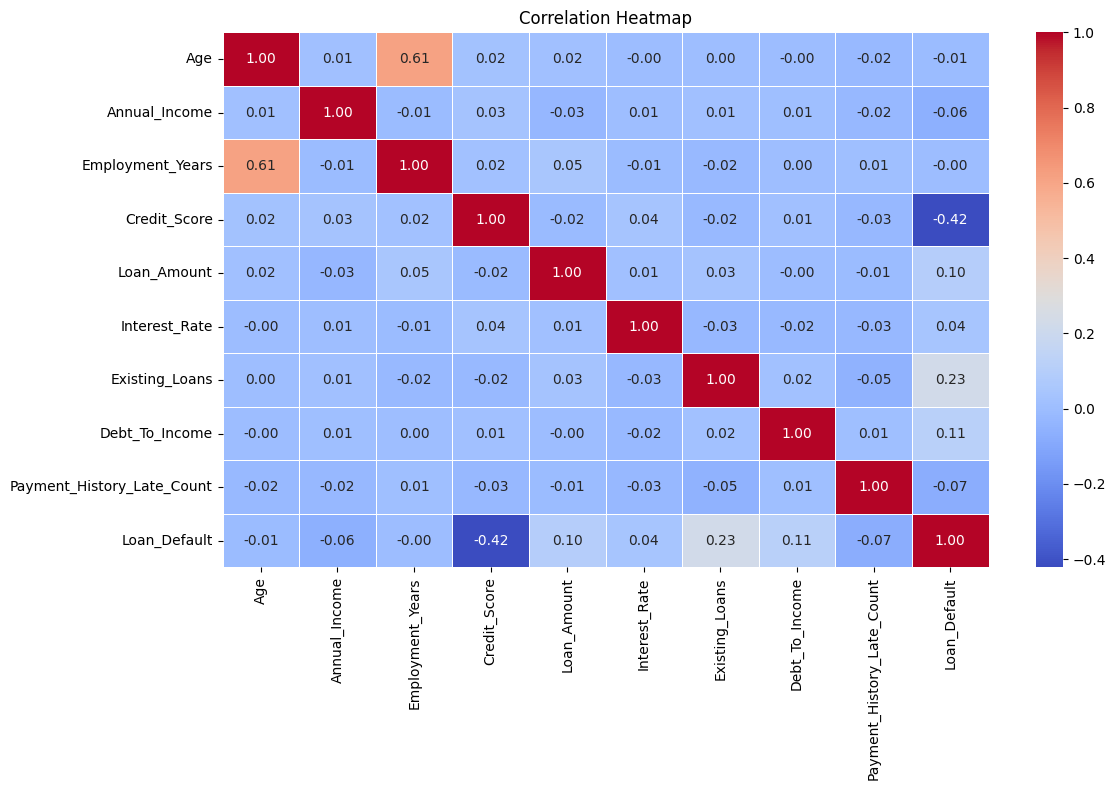


Feature Correlation with Loan_Default:
Existing_Loans                0.226147
Debt_To_Income                0.114331
Loan_Amount                   0.096074
Interest_Rate                 0.040363
Employment_Years             -0.000681
Age                          -0.009488
Annual_Income                -0.063503
Payment_History_Late_Count   -0.073116
Credit_Score                 -0.422247
Name: Loan_Default, dtype: float64


In [ ]:
# ============================================================
# STEP 6: CORRELATION ANALYSIS
# ============================================================

numeric_df = df_clean.select_dtypes(
    include=["number"]
)

correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Correlation with the target
target_correlation = (
    correlation_matrix["Loan_Default"]
    .drop("Loan_Default")
    .sort_values(ascending=False)
)

print("\nFeature Correlation with Loan_Default:")
print(target_correlation)

In [ ]:
# ============================================================
# STEP 7: FEATURE ENGINEERING AND DATA PREPARATION
# ============================================================

model_df = df_clean.copy()

# Create a derived feature
model_df["Loan_to_Income_Ratio"] = (
    model_df["Loan_Amount"] /
    model_df["Annual_Income"].clip(lower=1)
)

# Separate input features and target
X = model_df.drop(columns=["Loan_Default"])

y = model_df["Loan_Default"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(
    X,
    columns=["Education", "Employment_Type"],
    drop_first=True,
    dtype=int
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

display(X.head())

Feature matrix shape: (2000, 14)
Target shape: (2000,)

Input Features:
['Age', 'Annual_Income', 'Employment_Years', 'Credit_Score', 'Loan_Amount', 'Interest_Rate', 'Existing_Loans', 'Debt_To_Income', 'Payment_History_Late_Count', 'Loan_to_Income_Ratio', 'Education_High School', 'Education_Postgraduate', 'Employment_Type_Salaried', 'Employment_Type_Self-Employed']

Target Distribution:
Loan_Default
1    1145
0     855
Name: count, dtype: int64

Target Percentage:
Loan_Default
1    57.25
0    42.75
Name: proportion, dtype: float64


,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Interest_Rate,Existing_Loans,Debt_To_Income,Payment_History_Late_Count,Loan_to_Income_Ratio,Education_High School,Education_Postgraduate,Employment_Type_Salaried,Employment_Type_Self-Employed
0,59,1194257,30,715,510258,8.63,4,0.70,7,0.427260,1,0,1,0
1,49,198320,3,505,887742,17.22,2,0.23,7,4.476311,0,0,0,1
2,35,1114918,11,612,917190,7.23,5,0.11,2,0.822652,0,0,0,0
3,63,646758,22,794,193435,13.28,2,0.52,2,0.299084,1,0,0,0
4,28,1345225,1,639,528365,11.30,0,0.30,4,0.392771,1,0,0,1


In [ ]:
# ============================================================
# STEP 8: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Default Rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting Default Rate:")
print(round(y_test.mean() * 100, 2), "%")

Training Features: (1600, 14)
Testing Features: (400, 14)
Training Target: (1600,)
Testing Target: (400,)

Training Default Rate:
57.25 %

Testing Default Rate:
57.25 %


In [ ]:
# ============================================================
# STEP 9: LOGISTIC REGRESSION MODEL
# ============================================================

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

logistic_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression Model Trained Successfully!")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      round(accuracy_score(y_test, logistic_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test, logistic_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, logistic_predictions, zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, logistic_predictions, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test, logistic_probabilities
      ), 4))

Logistic Regression Model Trained Successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.70      0.66       171
           1       0.76      0.69      0.72       229

    accuracy                           0.69       400
   macro avg       0.69      0.70      0.69       400
weighted avg       0.70      0.69      0.70       400

Accuracy: 0.695
Precision: 0.756
Recall: 0.69
F1 Score: 0.7215
ROC-AUC: 0.7668


In [ ]:
# ============================================================
# STEP 10: RANDOM FOREST CLASSIFIER
# ============================================================

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

rf_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest Model Trained Successfully!")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test, rf_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, rf_predictions, zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, rf_predictions, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test, rf_probabilities
      ), 4))

Random Forest Model Trained Successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.65      0.65       171
           1       0.74      0.74      0.74       229

    accuracy                           0.70       400
   macro avg       0.70      0.70      0.70       400
weighted avg       0.70      0.70      0.70       400

Accuracy: 0.7025
Precision: 0.7391
Recall: 0.7424
F1 Score: 0.7407
ROC-AUC: 0.758


In [ ]:
# ============================================================
# STEP 11: GRADIENT BOOSTING CLASSIFIER
# ============================================================

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

gb_predictions = gradient_boosting_model.predict(X_test)

gb_probabilities = gradient_boosting_model.predict_proba(
    X_test
)[:, 1]

print("Gradient Boosting Model Trained Successfully!")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        gb_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      round(accuracy_score(y_test, gb_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test, gb_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, gb_predictions, zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, gb_predictions, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test, gb_probabilities
      ), 4))

Gradient Boosting Model Trained Successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.59      0.62       171
           1       0.72      0.77      0.74       229

    accuracy                           0.69       400
   macro avg       0.69      0.68      0.68       400
weighted avg       0.69      0.69      0.69       400

Accuracy: 0.695
Precision: 0.7166
Recall: 0.7729
F1 Score: 0.7437
ROC-AUC: 0.7624


Model Comparison Table:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.6950,0.7560,0.6900,0.7215,0.7668
1,Gradient Boosting,0.6950,0.7166,0.7729,0.7437,0.7624
2,Random Forest,0.7025,0.7391,0.7424,0.7407,0.7580


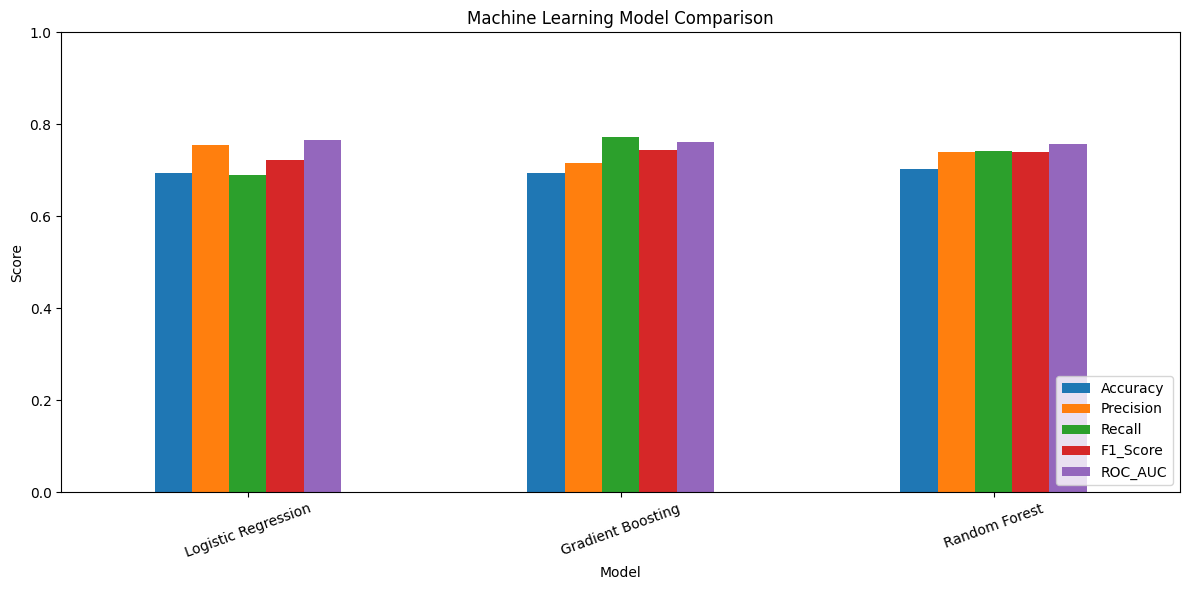

In [ ]:
# ============================================================
# STEP 12: MODEL PERFORMANCE COMPARISON
# ============================================================

results = []

model_outputs = {
    "Logistic Regression": (
        logistic_predictions,
        logistic_probabilities
    ),
    "Random Forest": (
        rf_predictions,
        rf_probabilities
    ),
    "Gradient Boosting": (
        gb_predictions,
        gb_probabilities
    )
}

for model_name, (predictions, probabilities) in model_outputs.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("Model Comparison Table:")
display(results_df.round(4))

# Plot model comparison
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Top-ranked model by ROC-AUC: Logistic Regression

Confusion Matrix:
[[120  51]
 [ 71 158]]


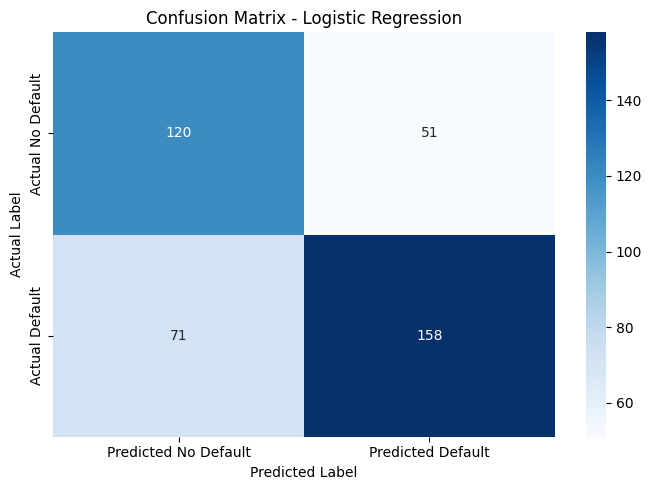

In [ ]:
# ============================================================
# STEP 13: CONFUSION MATRIX
# ============================================================

best_model_name = results_df.loc[0, "Model"]

predictions_by_name = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": rf_predictions,
    "Gradient Boosting": gb_predictions
}

best_predictions = predictions_by_name[best_model_name]

print("Top-ranked model by ROC-AUC:", best_model_name)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Default", "Predicted Default"],
    yticklabels=["Actual No Default", "Actual Default"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 14: ROC CURVE COMPARISON
# ============================================================

plt.figure(figsize=(9, 7))

<Figure size 900x700 with 0 Axes>

<Figure size 900x700 with 0 Axes>